Solves a Fokker-Planck equation of the form
$$\frac{\partial p(x,t)}{\partial t} = -\frac{\partial}{\partial x} \big[ \mu(x,t)p(x,t) \big] + \frac{1}{2}\sum_{k=1}^{m} \partial_{xx} \big[ \sigma_k^2(x,t)p(x,t) \big]$$
where
$$\mu, \sigma_1, \ldots, \sigma_m: [x_\ell,x_r] \times [0,T] \to \mathbb{R}$$
are continuously differentiable.

In [1]:
import numpy as np
import math
from scipy.linalg import solve_banded
from scipy.sparse import diags
import matplotlib.pyplot as plt
import scipy.special

'''
FPE_1D_Solver Class (FPE = Fokker-Planck Equation)

Stores data for a 1D FPE including the mesh, drift/noise functions, and initial condition.
Solves the FPE given an initial condition P0 defined on the domain of the mesh.
'''
class FPE_1D_solver:
    '''Initializes the class with drift and noise functions'''
    def __init__(self, mu=lambda x,t: 0, sigma_funcs=[lambda x,t: 0]):
        self.mu = lambda x,t: mu(x,t) + 0*x # Stores the drift function
        self.sigma_sqrd_array = np.array([(lambda x,t: 0.5*sigma(x,t)**2 + 0*x) for sigma in sigma_funcs]) # Stores the square of the noise functions
    
    '''Adjusts the mesh size and dt so they are uniform on the domain'''
    def __adjust_mesh_size__(self, x_left, x_right, h, t_end, dt):
        N = math.ceil((x_right - x_left)/h)
        h = (x_right - x_left)/N
        T = math.ceil(t_end/dt)
        dt = t_end/(T)
        self.N, self.h, self.T, self.dt = N, h, T, dt
        print(f'[Modified Mesh Settings] h = {h:.4f}, N = {N}, dt = {dt:.4f}, T = {T}')
        return h, N, dt, T

    '''Solves the FPE given the domain [x_left, x_right], an initial condition P0, mesh size, and dt'''
    def solve(self, x_left, x_right, P0, h, dt, t_end, method='implicit_euler'):
        self.initial_condition = P0 # Store initial condition
        
        h, N, dt, T = self.__adjust_mesh_size__(x_left, x_right, h, t_end, dt) # Adjust mesh size to be uniform

        # Generate arrays of x and t values
        x_arr = np.linspace(x_left, x_right, N+1, endpoint=True)
        t_arr = np.linspace(0, t_end, T+1, endpoint=True)
        self.x_arr, self.t_arr = x_arr, t_arr

        # Set initial condition
        P = np.zeros((T+1, N+1))
        P[0,:] = P0(x_arr)

        # Temp variable to reduce the number of computations for the Crank-Nicholson scheme
        matrix_diags = self.__generate_new_matrix_diags__(x_arr, N, t_arr[0], h) 

        # Determine the method given by the user
        match method:
            case 'crank-nicholson': step_func = self.__crank_nicholson_step__
            case 'implicit_euler': step_func = self.__implicit_euler_step__
            case _: raise ValueError(f'Unknown method: {method}')

        # Solve the FPE and return
        for n in range(T):
            P[n+1,:], matrix_diags = step_func(x_arr, N, t_arr[n+1], P[n,:], h, dt, matrix_diags)

        self.solution_matrix = P

        return x_arr, t_arr, P
    
    '''Sets up and solves the linear system given in the report'''
    def __implicit_euler_step__(self, x_arr, N, t_new, P_old, h, dt, *args):
        # Get the new M, C, and S matrices
        M_diags = self.__get_M_matrix_diags__(N, h)
        C_diags = self.__get_C_matrix_diags__(x_arr, N, t_new)
        S_diags = self.__get_S_matrix_diags__(x_arr, h, t_new)

        # Set up the linear system
        A_diags = [M_diags[i] - dt*(C_diags[i] - S_diags[i]) for i in range(3)]
        A_upper_diag_padded = np.insert(A_diags[2], 0, 0)
        A_lower_diag_padded = np.append(A_diags[1], 0)
        A_banded = np.array([A_upper_diag_padded, A_diags[0], A_lower_diag_padded])
        b = diags(M_diags, [0, -1, 1]) @ P_old

        # Solve the linear system
        P_new = solve_banded((1, 1), A_banded, b)
        return P_new, [M_diags, C_diags, S_diags]

    '''Sets up and solves the linear system given in the report'''
    def __crank_nicholson_step__(self, x_arr, N, t_new, P_old, h, dt, old_matrix_diags):
        new_M_diags, new_C_diags, new_S_diags = self.__generate_new_matrix_diags__(x_arr, N, t_new, h) # Get the new matrices at t_{n+1}
        old_M_diags, old_C_diags, old_S_diags = old_matrix_diags # The matrices at t_n

        # Set up the LHS of the linear system
        left_diags = [new_M_diags[i] - dt*(new_C_diags[i] - new_S_diags[i])*0.5 for i in range(3)]
        left_upper_diag_padded = np.insert(left_diags[2], 0, 0)
        left_lower_diag_padded = np.append(left_diags[1], 0)
        left_banded_matrix = np.array([left_upper_diag_padded, left_diags[0], left_lower_diag_padded])

        # Set up the RHS of the linear system
        right_diags = [old_M_diags[i] + dt*(old_C_diags[i] - old_S_diags[i])*0.5 for i in range(3)]
        b = diags(right_diags, [0, -1, 1]) @ P_old

        # Solve the linear system
        P_new = solve_banded((1, 1), left_banded_matrix, b)
        return P_new, [new_M_diags, new_C_diags, new_S_diags]
    
    '''Wrapper function to generate matrices'''
    def __generate_new_matrix_diags__(self, x_arr, N, t, h):
        M_diags = self.__get_M_matrix_diags__(N, h)
        C_diags = self.__get_C_matrix_diags__(x_arr, N, t)
        S_diags = self.__get_S_matrix_diags__(x_arr, h, t)
        return [M_diags, C_diags, S_diags]

    '''Generates the diagonals of M, using the formulas in the report'''
    def __get_M_matrix_diags__(self, N, h):
        main_diag = (2/3)*h * np.ones(N+1)
        main_diag[0] = h/3
        main_diag[-1] = h/3
        off_diag = h/6 * np.ones(N)
        return [main_diag, off_diag, off_diag]

    '''Generates the diagonals of C, using the formulas in the report'''
    def __get_C_matrix_diags__(self, x_arr, N, t):
        mu_array = self.mu(x_arr, t)
        main_diag = [mu_array[i-1]/6 - mu_array[i+1]/6 for i in range(1,N)]
        main_diag = np.insert(main_diag, 0, -mu_array[0]/3 - mu_array[1]/6)
        main_diag = np.append(main_diag, mu_array[-2]/6 + mu_array[-1]/3)
        lower_diag = [mu_array[i-1]/3 + mu_array[i]/6 for i in range(1,N+1)]
        upper_diag = [-mu_array[i+1]/3 - mu_array[i]/6 for i in range(0,N)]
        return [main_diag, lower_diag, upper_diag]

    '''Generates the diagonals of S, using the formulas in the report'''
    def __get_S_matrix_diags__(self, x_arr, h, t):
        sigma_sqrd = np.sum([s(x_arr, t) for s in self.sigma_sqrd_array], axis=0)
        main_diag = 2*sigma_sqrd/h
        main_diag[0] = 0.5*main_diag[0]
        main_diag[-1] = 0.5*main_diag[-1]
        lower_diag = -sigma_sqrd[:-1]/h
        upper_diag = -sigma_sqrd[1:]/h
        return [main_diag, lower_diag, upper_diag]

### Some numerical tests

[Modified Mesh Settings] h = 0.0010, N = 10000, dt = 0.0500, T = 100
Initial Mass:1.0
Final Mass:1.0005631781876407


Text(0.5, 0.98, '$P(x,t)$')

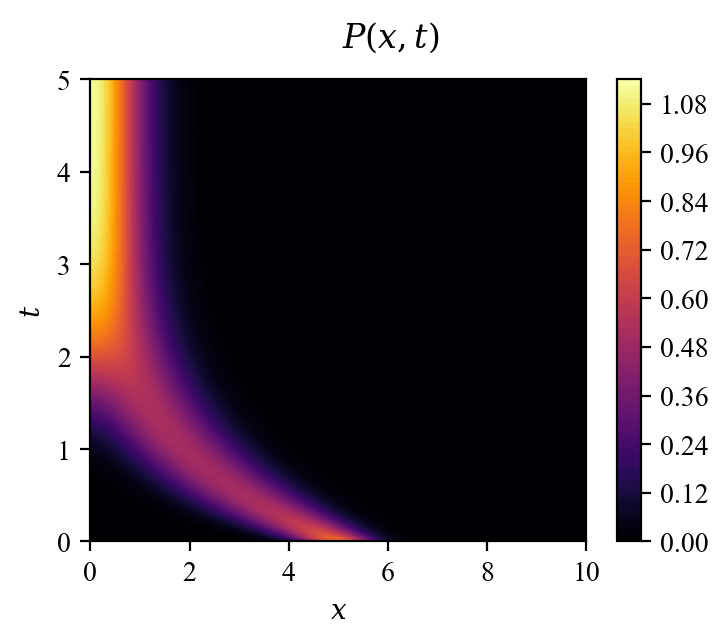

In [2]:
mu = lambda x,t: -x
sigma_funcs = [lambda x,t: 1]

myPDEobj = FPE_1D_solver(mu=mu, sigma_funcs=sigma_funcs)

def bump_function(x, x_left, x_right, mu=0, sigma=1):
    c = sigma * math.sqrt(np.pi/2) * (math.erf((x_right - mu)/(sigma*math.sqrt(2))) - math.erf((x_left - mu)/(sigma*math.sqrt(2))))
    return np.exp(-0.5*((x - mu)/sigma)**2) / c

L = 10
P0 = lambda x: bump_function(x, x_left=0, x_right=L, mu=5, sigma=0.5)
h = 0.001
dt = 0.05
t_end = 5

x_arr, t_arr, P = myPDEobj.solve(x_left=0, x_right=L, P0=P0, h=h, dt=dt, t_end=t_end)

print('Initial Mass:' + str(np.sum(P[0,:])*(x_arr[1] - x_arr[0])))
print('Final Mass:' + str(np.sum(P[-1,:])*(x_arr[1] - x_arr[0])))

import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['mathtext.fontset'] = 'dejavuserif'

fig, ax = plt.subplots(1, 1, figsize=(4, 3), dpi=200)

cf = ax.contourf(x_arr, t_arr, P, levels=100, cmap='inferno')

ax.set_xlabel(r'$x$')
ax.set_ylabel(r'$t$')

fig.colorbar(cf)

fig.suptitle(r'$P(x,t)$')

[Modified Mesh Settings] h = 0.0010, N = 10000, dt = 0.0500, T = 100
Initial Mass:1.0
Final Mass:0.9999999998632859


Text(0.5, 0.98, '$P(x,t)$')

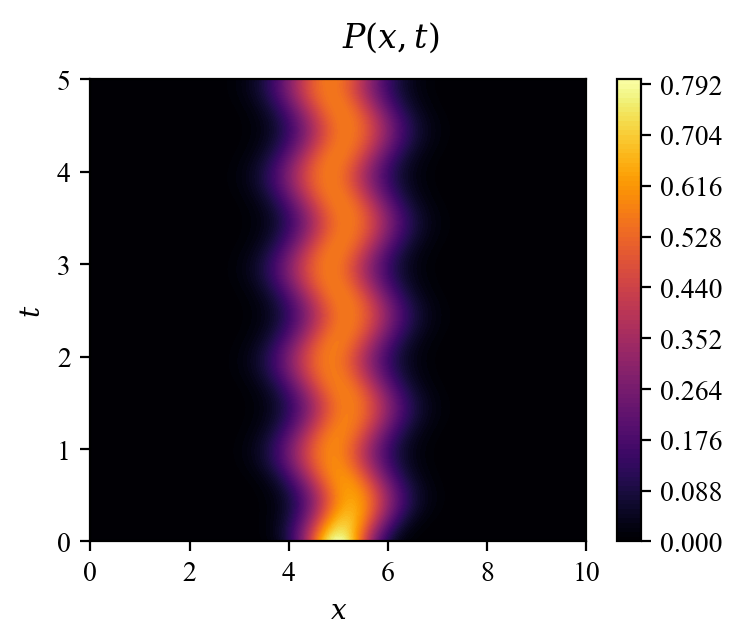

In [3]:
def mu(x,t): 
    return np.sin(2*np.pi*t) + 5-x
sigma_funcs = [lambda x,t: 1]

L = 10
P0 = lambda x: bump_function(x, x_left=0, x_right=L, mu=5, sigma=0.5)
h = 0.001
dt = 0.05
t_end = 5

myPDEobj = FPE_1D_solver(mu=mu, sigma_funcs=sigma_funcs)
x_arr, t_arr, P = myPDEobj.solve(x_left=0, x_right=L, P0=P0, h=h, dt=dt, t_end=t_end)

print('Initial Mass:' + str(np.sum(P[0,:])*(x_arr[1] - x_arr[0])))
print('Final Mass:' + str(np.sum(P[-1,:])*(x_arr[1] - x_arr[0])))

fig, ax = plt.subplots(1, 1, figsize=(4, 3), dpi=200)

cf = ax.contourf(x_arr, t_arr, P, levels=100, cmap='inferno')

ax.set_xlabel(r'$x$')
ax.set_ylabel(r'$t$')

fig.colorbar(cf)

fig.suptitle(r'$P(x,t)$')

### Comparing the Implicit Euler and Crank-Nicholson Schemes for the Cox-Ingersoll-Ross Process

[Modified Mesh Settings] h = 0.0100, N = 500, dt = 0.0699, T = 286
[Modified Mesh Settings] h = 0.0100, N = 500, dt = 0.0699, T = 286


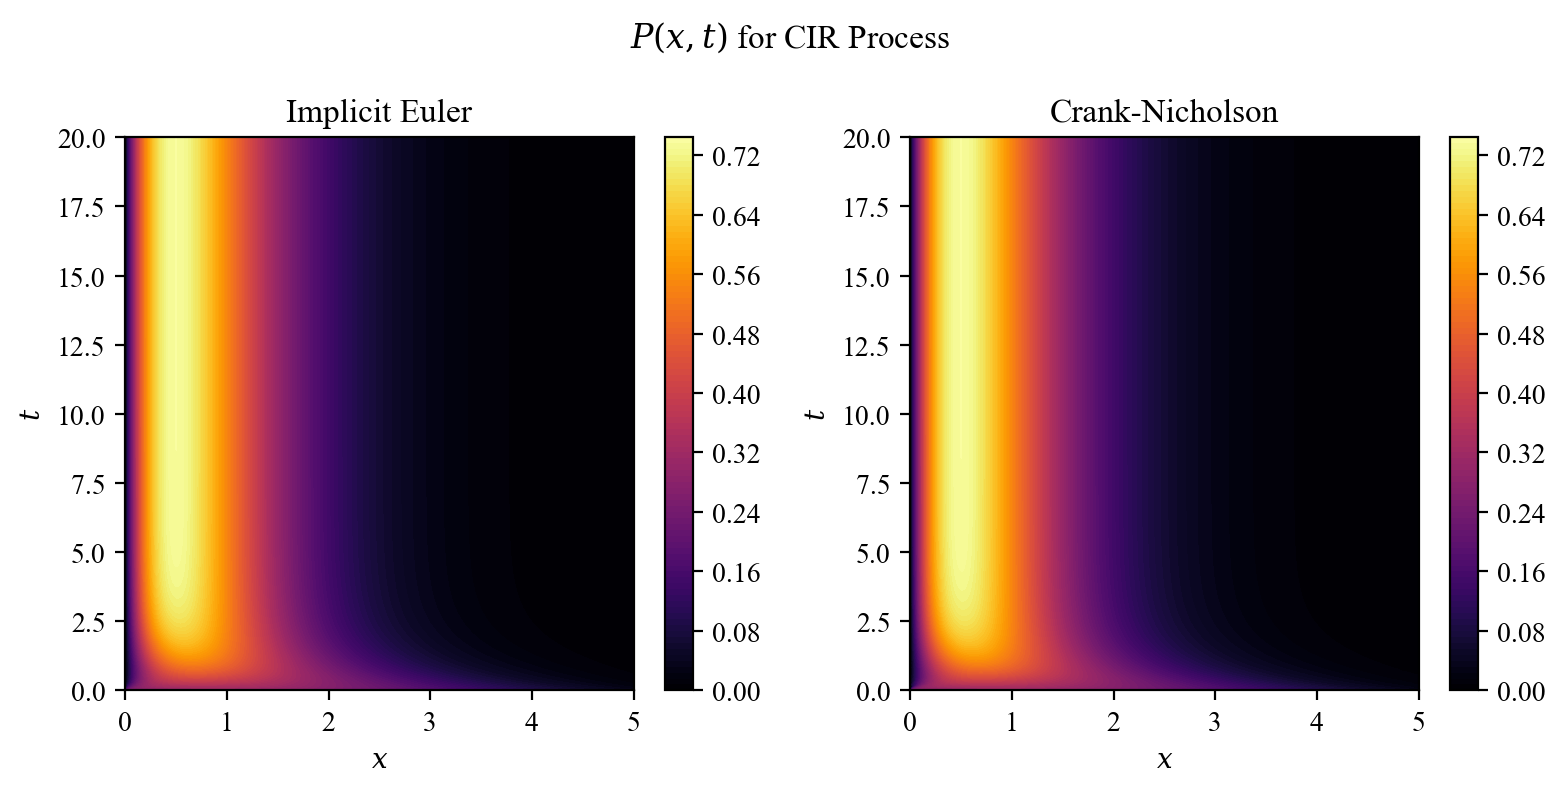

In [4]:
kappa = 1
theta = 1
sigma = 1

mu = lambda x,t: kappa*(theta - x)
sigma_funcs = [lambda x,t: sigma*np.sqrt(x)]

L = 5
P0 = lambda x: bump_function(x, x_left=0, x_right=L, mu=1, sigma=2)
h = 0.01
dt = 0.07
t_end = 20

CIR_eqn = FPE_1D_solver(mu=mu, sigma_funcs=sigma_funcs)
x_arr_IE, t_arr_IE, P_CIR_IE = CIR_eqn.solve(x_left=0, x_right=L, P0=P0, h=h, dt=dt, t_end=t_end, method='implicit_euler')
x_arr_CN, t_arr_CN, P_CIR_CN = CIR_eqn.solve(x_left=0, x_right=L, P0=P0, h=h, dt=dt, t_end=t_end, method='crank-nicholson')

fig, ax = plt.subplots(1, 2, figsize=(8, 4), dpi=200)

P_CIR_CN_abs = np.abs(P_CIR_CN[:,:])

cf_IE = ax[0].contourf(x_arr_IE, t_arr_IE, P_CIR_IE, levels=100, cmap='inferno')
cf_CN = ax[1].contourf(x_arr_CN, t_arr_CN, P_CIR_CN_abs, levels=100, cmap='inferno')

ax[0].set_xlabel(r'$x$')
ax[0].set_ylabel(r'$t$')
ax[1].set_xlabel(r'$x$')
ax[1].set_ylabel(r'$t$')

ax[0].set_title('Implicit Euler')
ax[1].set_title('Crank-Nicholson')

fig.colorbar(cf_IE, ax=ax[0])
fig.colorbar(cf_CN, ax=ax[1])

fig.suptitle(r'$P(x,t)$ for CIR Process')

fig.tight_layout()

plt.savefig('Figures/CN_vs_IE_CIR.png', dpi=200, bbox_inches='tight')

CN L1 Error: 0.000056
CN L2 Error: 0.000065
IE L1 Error: 0.000053
IE L2 Error: 0.000063
-0.1606806746105616
0.000142173478936194


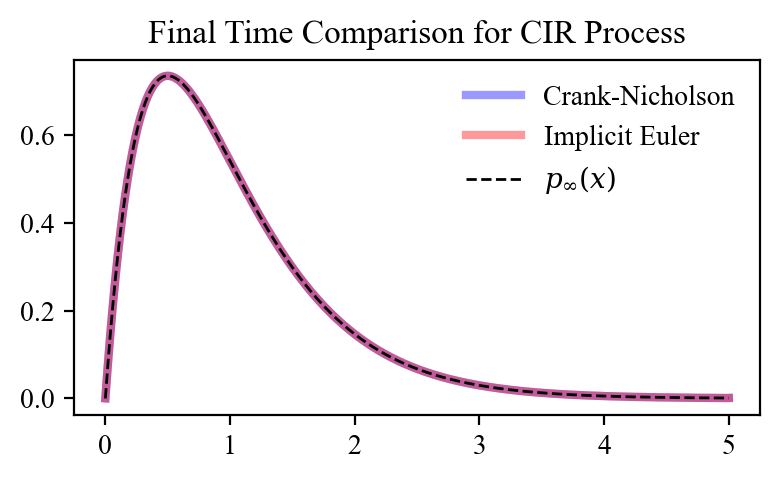

In [5]:
def p_infty(x, kappa=1, theta=1, sigma=1):
    beta = (2*kappa)/(sigma*sigma)
    alpha = (2*kappa*theta)/(sigma*sigma)
    return ( (beta**alpha) / scipy.special.gamma(alpha) ) * (x**(alpha-1)) * np.exp(-beta*x)

p_infty_normalized = p_infty(x_arr_IE) / np.trapezoid(p_infty(x_arr_IE), x_arr_IE)

crank_nicholson_L1_error = np.trapezoid(np.abs(P_CIR_CN[-1,:] - p_infty_normalized), x_arr_IE)
print(f'CN L1 Error: {crank_nicholson_L1_error:.6f}')

crank_nicholson_L2_error = np.sqrt(np.trapezoid((P_CIR_CN[-1,:] - p_infty_normalized)**2, x_arr_IE))
print(f'CN L2 Error: {crank_nicholson_L2_error:.6f}')

implicit_euler_L1_error = np.trapezoid(np.abs(P_CIR_IE[-1,:] - p_infty_normalized), x_arr_IE)
print(f'IE L1 Error: {implicit_euler_L1_error:.6f}')

implicit_euler_L2_error = np.sqrt(np.trapezoid((P_CIR_IE[-1,:] - p_infty_normalized)**2, x_arr_IE))
print(f'IE L2 Error: {implicit_euler_L2_error:.6f}')

print(np.min(P_CIR_CN[:,:]))
print(np.min(P_CIR_IE[:,:]))

fig, ax = plt.subplots(1, 1, figsize=(4, 2.5), dpi=200)

ax.plot(x_arr_IE, P_CIR_CN[-1,:], label='Crank-Nicholson', color='b', linewidth=3, alpha=0.4)
ax.plot(x_arr_IE, P_CIR_IE[-1,:], label='Implicit Euler', color='r', linewidth=3, alpha=0.4)

ax.plot(x_arr_IE, p_infty_normalized, label=r'$p_\infty(x)$', linestyle='dashed', color='k', linewidth=1)

ax.legend(fontsize=10, framealpha=1, frameon=False)

ax.set_title('Final Time Comparison for CIR Process')

fig.tight_layout()
plt.savefig('Figures/CN_vs_IE_CIR_final_time_comparison.png', dpi=200, bbox_inches='tight')

### Comparing the Implicit Euler and Crank-Nicholson Schemes for the Ornstein-Uhlenbeck Process

[Modified Mesh Settings] h = 0.0100, N = 1600, dt = 0.0694, T = 72
[Modified Mesh Settings] h = 0.0100, N = 1600, dt = 0.0694, T = 72


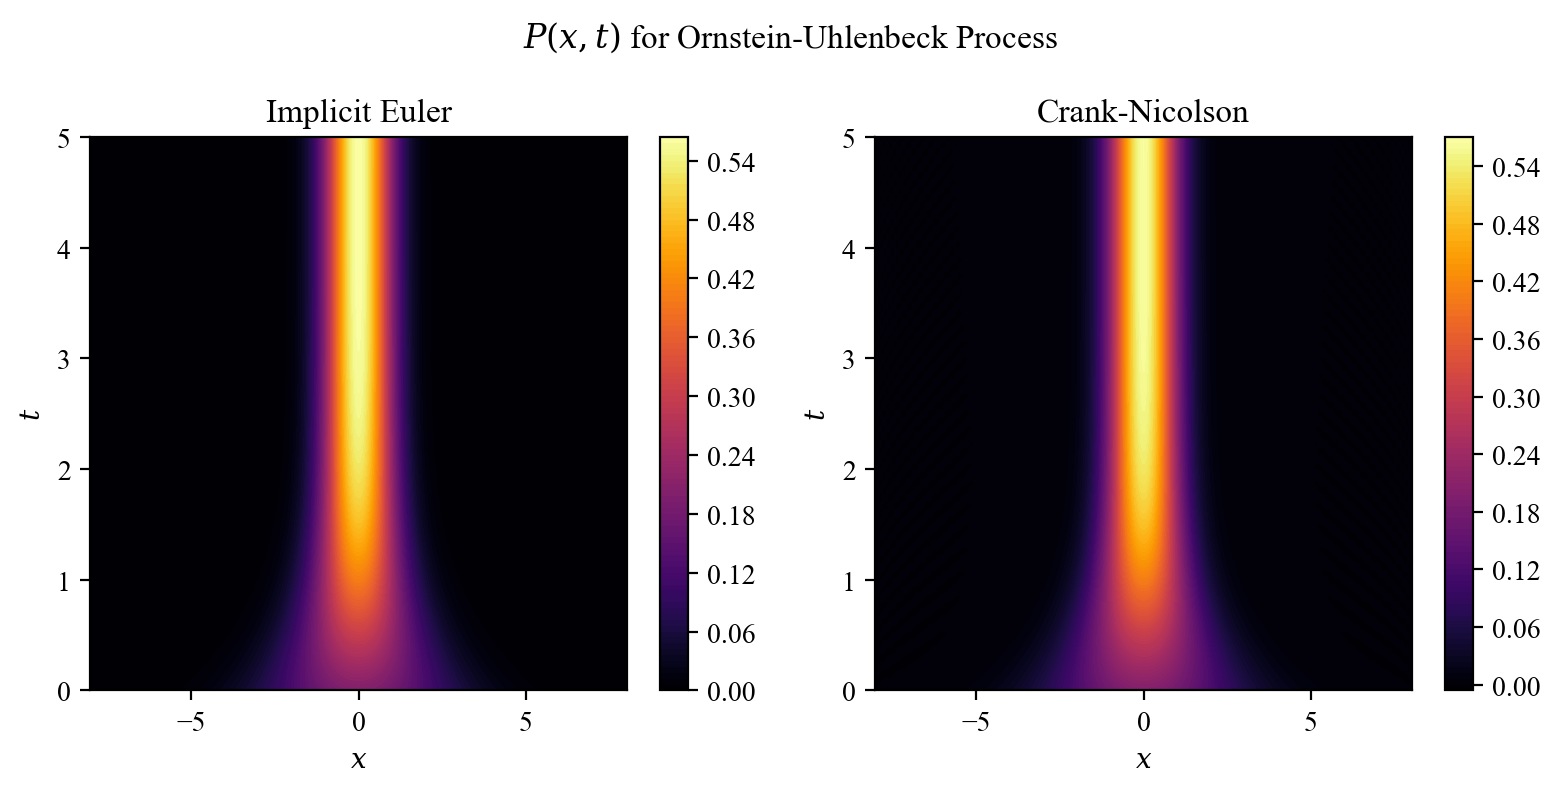

In [6]:
from scipy.stats import norm

a = 1
b = 1

mu = lambda x,t: -a*x
sigma_funcs = [lambda x,t: b]

x_left = -8
x_right = 8
P0 = lambda x: norm.pdf(x, loc=0, scale=2)
h = 0.01
dt = 0.07
t_end = 5

ornstein_uhlenbeck_eqn = FPE_1D_solver(mu=mu, sigma_funcs=sigma_funcs)
x_arr_OU_CN, t_arr_OU_CN, P_OU_CN = ornstein_uhlenbeck_eqn.solve(x_left=x_left, x_right=x_right, P0=P0, h=h, dt=dt, t_end=t_end, method='crank-nicholson')
x_arr_OU_IE, t_arr_OU_IE, P_OU_IE = ornstein_uhlenbeck_eqn.solve(x_left=x_left, x_right=x_right, P0=P0, h=h, dt=dt, t_end=t_end, method='implicit_euler')

fig, ax = plt.subplots(1, 2, figsize=(8, 4), dpi=200)

cf_IE = ax[0].contourf(x_arr_OU_IE, t_arr_OU_IE, P_OU_IE, levels=100, cmap='inferno')
cf_CN = ax[1].contourf(x_arr_OU_CN, t_arr_OU_CN, P_OU_CN, levels=100, cmap='inferno')

ax[0].set_xlabel(r'$x$')
ax[0].set_ylabel(r'$t$')
ax[1].set_xlabel(r'$x$')
ax[1].set_ylabel(r'$t$')

ax[0].set_title('Implicit Euler')
ax[1].set_title('Crank-Nicolson')

fig.colorbar(cf_IE, ax=ax[0])
fig.colorbar(cf_CN, ax=ax[1])

fig.suptitle(r'$P(x,t)$ for Ornstein-Uhlenbeck Process')

plt.tight_layout()

plt.savefig('Figures/CN_vs_IE_ornstein_uhlenbeck.png', dpi=200, bbox_inches='tight')

CN L1 Error: 0.000171
CN L2 Error: 0.000110
IE L1 Error: 0.000307
IE L2 Error: 0.000186


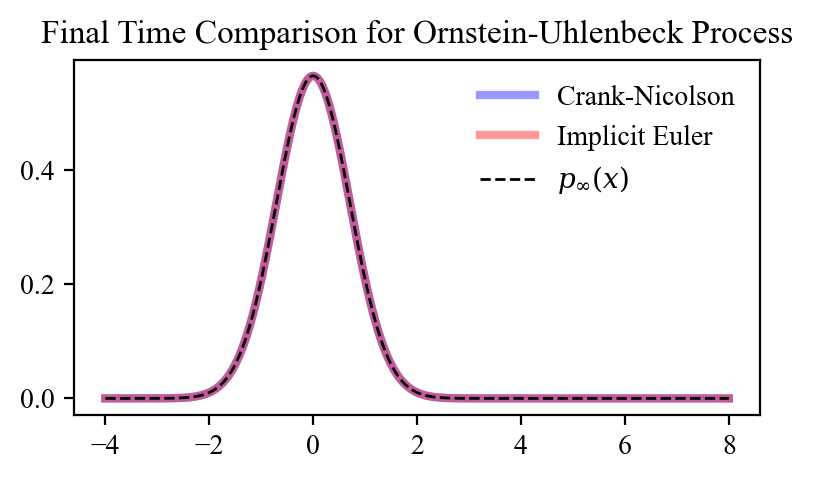

In [7]:
def p_infty_ornstein_uhlenbeck(x, a=1, b=1):
    sigma = b**2/(2*a)
    return np.exp(-x**2 / (2*sigma)) / (np.sqrt(2*np.pi*sigma))

x_arr_plot_indices = np.where(x_arr_OU_CN >= -4)[0]
x_arr_OU_CN_plot = x_arr_OU_CN[x_arr_plot_indices]
x_arr_OU_IE_plot = x_arr_OU_IE[x_arr_plot_indices]

crank_nicholson_error = np.trapezoid(np.abs(P_OU_CN[-1,x_arr_plot_indices] - p_infty_ornstein_uhlenbeck(x_arr_OU_CN_plot)), x_arr_OU_CN_plot)
print(f'CN L1 Error: {crank_nicholson_error:.6f}')

crank_nicholson_L2_error = np.sqrt(np.trapezoid((P_OU_CN[-1,x_arr_plot_indices] - p_infty_ornstein_uhlenbeck(x_arr_OU_CN_plot))**2, x_arr_OU_CN_plot))
print(f'CN L2 Error: {crank_nicholson_L2_error:.6f}')

implicit_euler_error = np.trapezoid(np.abs(P_OU_IE[-1,x_arr_plot_indices] - p_infty_ornstein_uhlenbeck(x_arr_OU_IE_plot)), x_arr_OU_IE_plot)
print(f'IE L1 Error: {implicit_euler_error:.6f}')

implicit_euler_L2_error = np.sqrt(np.trapezoid((P_OU_IE[-1,x_arr_plot_indices] - p_infty_ornstein_uhlenbeck(x_arr_OU_IE_plot))**2, x_arr_OU_IE_plot))
print(f'IE L2 Error: {implicit_euler_L2_error:.6f}')

fig, ax = plt.subplots(1, 1, figsize=(4, 2.5), dpi=200)

ax.plot(x_arr_OU_CN_plot, P_OU_CN[-1,x_arr_plot_indices], label='Crank-Nicolson', color='b', linewidth=3, alpha=0.4)
ax.plot(x_arr_OU_IE_plot, P_OU_IE[-1,x_arr_plot_indices], label='Implicit Euler', color='r', linewidth=3, alpha=0.4)

ax.plot(x_arr_OU_CN_plot, p_infty_ornstein_uhlenbeck(x_arr_OU_CN_plot), label=r'$p_\infty(x)$', linestyle='dashed', color='k', linewidth=1)

ax.legend(fontsize=10, framealpha=1, frameon=False)

ax.set_title('Final Time Comparison for Ornstein-Uhlenbeck Process')

fig.tight_layout()
plt.savefig('Figures/CN_vs_IE_ornstein_uhlenbeck_final_time_comparison.png', dpi=200, bbox_inches='tight')

### Does the CFL condition need to be met for solvability? No.

In [8]:
kappa = 1
theta = 1
sigma = 1

mu = lambda x,t: kappa*(theta - x)
sigma_funcs = [lambda x,t: sigma*np.sqrt(x)]

L = 5
P0 = lambda x: bump_function(x, x_left=0, x_right=L, mu=1, sigma=2)
h = 0.005
dt = 0.007
t_end = 20

CIR_eqn = FPE_1D_solver(mu=mu, sigma_funcs=sigma_funcs)
x_arr, t_arr, P_CIR = CIR_eqn.solve(x_left=0, x_right=L, P0=P0, h=h, dt=dt, t_end=t_end, method='crank-nicholson')

M = np.max(np.abs(mu(x_arr, 0) - np.append(np.sum([np.diff(s(x_arr, 0)**2) for s in sigma_funcs], axis=0)/2,0)))

CFL_number = h / (M*math.sqrt(12))

print(f'CFL Number: {CFL_number:.4f}')
print('CFL Condition Met?', dt < CFL_number)
print(f'Overshooting Detected? {np.any(P_CIR < 0)} ({np.sum(P_CIR < 0)} instances)')

[Modified Mesh Settings] h = 0.0050, N = 1000, dt = 0.0070, T = 2858
CFL Number: 0.0004
CFL Condition Met? False
Overshooting Detected? False (0 instances)
